# ACDC Cardiac MRI: Segmentation and Diagnosis
**CMPS 261, Group 26: Mohamad Alame, Sarra Fassakh**

The problem has two parts:
1. **Segmentation:** label every pixel of a heart MRI slice as right ventricle, myocardium (muscle wall), left ventricle or background.
2. **Diagnosis:** use measurements from those outlines to predict one of five patient groups.

Sections 1–7 run in a few minutes. They preprocess the data, load our saved trained models and recompute the results from them. The full training code is in the appendix, behind `RUN_TRAINING`, because training everything took about 2.5 hours.

## 1. Setup

In [1]:
import glob, json, os, re, sys, time
import numpy as np, pandas as pd, joblib, nibabel as nib, torch, torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy import ndimage as ni
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, os.getcwd())
from acdc_forest_baseline import CROP, DATA, MODEL_DIR, OUT, SPACING, features, load_patient, scores

TEST_DATA = DATA.replace("training", "testing")
device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
RUN_TRAINING = False          # True reruns all training in the appendix (about 2.5 hours)
experiments = json.load(open(os.path.join(OUT, "experiments.json")))
print("device:", device, "| data found:", os.path.isdir(DATA), "| models found:", os.path.isdir(MODEL_DIR))

device: mps | data found: True | models found: True


## 2. Data loading and preprocessing

The scans are NIfTI files, read with `nibabel`. For every patient we take the two labelled moments (heart full and heart squeezed) and:
- **normalise brightness per scan**, clipping the extreme 1% and scaling to 0–1, because MRI brightness has no fixed scale;
- **split each 3D scan into 2D slices**;
- **resize to 1.5 mm per pixel**, so the same organ has the same size in pixels for every patient (nearest-neighbour for outlines, so labels stay valid);
- **crop or pad to 192 × 192**.

Patients, not slices, are split: 80 training, 20 validation (4 per group), and the official 50 test patients kept aside. The preprocessing code is `load_patient` in `acdc_forest_baseline.py` (appendix A).

In [2]:
split = json.load(open(os.path.join(OUT, "split.json")))
t0 = time.time()
data, kept, total = {}, 0, 0
for n in split["train"] + split["val"]:
    s, k, t = load_patient(os.path.join(DATA, n))
    data[n], kept, total = s, kept + k, total + t
test = {os.path.basename(p): load_patient(p)[0] for p in sorted(glob.glob(glob.escape(TEST_DATA) + "/patient*"))}
tr = [s for n in split["train"] for s in data[n]]
va = [s for n in split["val"] for s in data[n]]
te = [s for n in sorted(test) for s in test[n]]
print(f"preprocessed in {time.time() - t0:.0f} s: {len(tr)} train, {len(va)} validation, {len(te)} test slices")
print(f"heart pixels kept after cropping: {kept / total:.2%}")

raw = [np.percentile(np.asarray(nib.load(f).dataobj), 99) for f in sorted(glob.glob(glob.escape(DATA) + "/patient*/*_frame??.nii.gz"))]
print(f"bright end (99th percentile) across raw scans: {min(raw):.0f} to {max(raw):.0f}  -> why we normalise")

preprocessed in 6 s: 1526 train, 376 validation, 1076 test slices
heart pixels kept after cropping: 100.00%


bright end (99th percentile) across raw scans: 135 to 1176  -> why we normalise


In [3]:
s = va[len(va) // 2]
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(s["img"].T, cmap="gray"); ax[0].set_title("preprocessed slice")
ax[1].imshow(s["img"].T, cmap="gray"); ax[1].imshow(np.ma.masked_where(s["mask"].T == 0, s["mask"].T), cmap="jet", alpha=.5)
ax[1].set_title("expert outline")
for a in ax: a.axis("off")
plt.show()

## 3. Classical baseline: random forest

Each pixel becomes one row of 11 features (brightness, blurred brightness at four sizes, edge strength, brightness against surroundings, three position values, slice position). We sample up to 300 heart and 1,200 background pixels per slice. Tuning, in `acdc_forest_baseline.py` (appendix A), searched the background sampling, class weights, depth, leaf size, features per split and number of trees on the validation patients. Below are the saved tuning trials and final validation results.

In [4]:
display(pd.read_csv(os.path.join(OUT, "tuning.csv"))[["stage", "bg", "class_weight", "depth", "leaf", "max_features", "trees", "macro_f1", "mean_precision", "mean_recall", "train_s"]])
fr = json.load(open(os.path.join(OUT, "forest_results.json")))
print("chosen settings:", fr["best_config"])
print("validation macro F1:", fr["validation"]["macro_f1"], "| 5-fold by patient:", fr["cv5_mean"], "±", fr["cv5_std"])
print("feature importance:", fr["feature_importance"])
print("without position features (validation macro F1):", experiments["forest_without_position"]["validation"]["macro_f1"])

,stage,bg,class_weight,depth,leaf,max_features,trees,macro_f1,mean_precision,mean_recall,train_s
0,1 sampling,300,balanced,20,5,sqrt,100,0.4921,0.3759,0.7787,45.7
1,1 sampling,300,NaN,20,5,sqrt,100,0.5489,0.4483,0.7532,39.7
2,1 sampling,1200,balanced,20,5,sqrt,100,0.5079,0.3949,0.7710,142.0
3,1 sampling,1200,NaN,20,5,sqrt,100,0.5897,0.5473,0.6510,103.8
4,1 sampling,3000,balanced,20,5,sqrt,100,0.5207,0.4107,0.7663,329.4
5,1 sampling,3000,NaN,20,5,sqrt,100,0.5702,0.6117,0.5364,235.5
6,2 forest,1200,NaN,12,5,sqrt,100,0.5727,0.5284,0.6431,89.4
7,2 forest,1200,NaN,30,5,sqrt,100,0.5896,0.5501,0.6447,99.9
8,2 forest,1200,NaN,20,1,sqrt,100,0.5889,0.5465,0.6500,97.0
9,2 forest,1200,NaN,20,20,sqrt,100,0.5894,0.5467,0.6517,96.5


chosen settings: {'fg': 300, 'bg': 1200, 'trees': 200, 'depth': 20, 'leaf': 5, 'max_features': 'sqrt', 'class_weight': None}
validation macro F1: 0.5901 | 5-fold by patient: 0.5843 ± 0.0196
feature importance: {'distance from centre': 0.4004, 'y position': 0.1326, 'x position': 0.0891, 'blur s=4': 0.0581, 'slice position': 0.0516, 'brightness': 0.0513, 'blur s=1': 0.0481, 'blur s=8': 0.0475, 'brightness vs surroundings': 0.0466, 'blur s=2': 0.0448, 'edge strength': 0.0298}
without position features (validation macro F1): 0.1546


## 4. U-Net

The same U-Net design as in our experiments: it shrinks the slice three times to see context, then expands it back, reusing detail. Below we load the chosen saved model (E: augmentation + Dice loss, 80 epochs) and recompute its validation score.

In [5]:
def confusion(pred, true):
    return np.bincount((np.asarray(true).reshape(-1).astype(np.int64) * 4 + np.asarray(pred).reshape(-1)), minlength=16).reshape(4, 4)


def breakdown(preds, slices):
    """Macro F1 overall and by moment, slice position and group."""
    def sub(cond):
        i = [k for k, s in enumerate(slices) if cond(s)]
        return scores(sum(confusion(preds[k], slices[k]["mask"]) for k in i))["macro_f1"]
    third = lambda s: "first third" if s["z"] < 1 / 3 else ("middle" if s["z"] < 2 / 3 else "last third")
    return dict(by_moment={m: sub(lambda s, m=m: s["moment"] == m) for m in ("ED", "ES")},
                by_slice_position={p: sub(lambda s, p=p: third(s) == p) for p in ("first third", "middle", "last third")},
                by_group={g: sub(lambda s, g=g: s["group"] == g) for g in sorted({s["group"] for s in slices})})


def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())


class UNet(nn.Module):
    """Same design as the pilot: shrink 3 times to see context, expand back to reuse detail."""

    def __init__(self, b=16):
        super().__init__()
        self.d1, self.d2, self.d3 = block(1, b), block(b, 2 * b), block(2 * b, 4 * b)
        self.mid = block(4 * b, 8 * b)
        self.u3, self.c3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, 2), block(8 * b, 4 * b)
        self.u2, self.c2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, 2), block(4 * b, 2 * b)
        self.u1, self.c1 = nn.ConvTranspose2d(2 * b, b, 2, 2), block(2 * b, b)
        self.out, self.pool = nn.Conv2d(b, 4, 1), nn.MaxPool2d(2)

    def forward(self, x):
        a = self.d1(x)
        c = self.d2(self.pool(a))
        d = self.d3(self.pool(c))
        m = self.mid(self.pool(d))
        d = self.c3(torch.cat([self.u3(m), d], 1))
        c = self.c2(torch.cat([self.u2(d), c], 1))
        return self.out(self.c1(torch.cat([self.u1(c), a], 1)))


def tensors(slices):
    return (torch.tensor(np.stack([s["img"] for s in slices]))[:, None].float(),
            torch.tensor(np.stack([s["mask"] for s in slices])).long())


def predict(model, x, probs=False):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), 32):
            p = model(x[i:i + 32].to(device)).softmax(1).cpu()
            out.append(p if probs else p.argmax(1))
    return torch.cat(out)

parameters: 483204


validation macro F1 (recomputed): 0.9197


,name,parameters,epochs,train_seconds,val_macro_f1
0,"A: pilot (no augmentation, cross-entropy)",483204,30,617.8,0.9017
1,B: + augmentation,483204,40,874.1,0.9086
2,C: + augmentation + Dice loss,483204,40,880.8,0.9139
3,D: wider (32) + aug + Dice,1927940,40,1875.6,0.9149
4,"E: aug + Dice, 80 epochs",483204,80,1818.5,0.9197


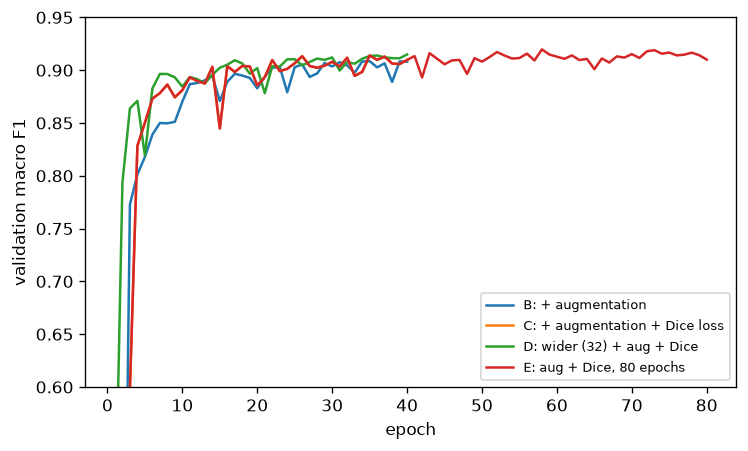

In [6]:
unet = UNet(16).to(device)
unet.load_state_dict(torch.load(os.path.join(MODEL_DIR, "acdc_unet_E.pt"), map_location=device))
print("parameters:", sum(p.numel() for p in unet.parameters()))
xv, yv = tensors(va)
print("validation macro F1 (recomputed):", scores(confusion(predict(unet, xv), yv))["macro_f1"])
display(pd.DataFrame([experiments["unet_pilot"]] + experiments["unet_variants"])[["name", "parameters", "epochs", "train_seconds", "val_macro_f1"]])
display(Image(os.path.join(OUT, "unet_variants_curves.png")))

## 5. Diagnosis models

Twelve measurements per patient from the outlines: volumes, ejection fractions, muscle mass, body-size-adjusted values and the thickest wall. We compare logistic regression at five strengths of regularisation with 5-fold cross-validation repeated 5 times, on the 100 training patients' expert outlines.

In [7]:
def meta(path):
    info = dict(re.findall(r"(\w+): (\S+)", open(os.path.join(path, "Info.cfg")).read()))
    z = float(nib.load(glob.glob(glob.escape(path) + "/*_frame??.nii.gz")[0]).header.get_zooms()[2])
    return info, z


def measure(ed, es, z, h, w):
    """12 measurements from outline stacks (slices x 192 x 192, at 1.5 mm pixels)."""
    ml = SPACING * SPACING * z / 1000
    lv_ed, lv_es = (ed == 3).sum() * ml, (es == 3).sum() * ml
    rv_ed, rv_es = (ed == 1).sum() * ml, (es == 1).sum() * ml
    mass = (ed == 2).sum() * ml * 1.05
    bsa = np.sqrt(h * w / 3600)
    thick = max(2 * ni.distance_transform_edt(sl == 2, sampling=SPACING).max() for sl in ed)
    lv_ef = (lv_ed - lv_es) / max(lv_ed, 1e-6)
    rv_ef = (rv_ed - rv_es) / max(rv_ed, 1e-6)
    return [lv_ed, lv_es, lv_ef, rv_ed, rv_es, rv_ef, mass, lv_ed / bsa, rv_ed / bsa, mass / bsa,
            rv_ed / max(lv_ed, 1e-6), thick]


MEASURES = ["lv_edv", "lv_esv", "lv_ef", "rv_edv", "rv_esv", "rv_ef", "muscle_mass", "lv_edv_per_m2",
            "rv_edv_per_m2", "mass_per_m2", "rv_lv_ratio", "max_thickness"]


def patient_table(names, root, slices, preds=None):
    """One row of measurements per patient, from expert outlines or from predictions."""
    rows, groups = [], []
    for n in names:
        info, z = meta(os.path.join(root, n))
        idx = {m: [i for i, s in enumerate(slices) if s["patient"] == n and s["moment"] == m] for m in ("ED", "ES")}
        get = (lambda i: slices[i]["mask"]) if preds is None else (lambda i: np.asarray(preds[i]).reshape(CROP, CROP))
        ed = np.stack([get(i) for i in idx["ED"]])
        es = np.stack([get(i) for i in idx["ES"]])
        rows.append(measure(ed, es, z, float(info["Height"]), float(info["Weight"])))
        groups.append(info.get("Group", "?"))
    return np.array(rows), np.array(groups)

In [8]:
names = sorted(split["train"] + split["val"])
Xd, yd = patient_table(names, DATA, [s for n in names for s in data[n]])
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=261)
for c in (0.01, 0.1, 1, 10, 100):
    sc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000)), Xd, yd, cv=cv)
    print(f"logistic regression C={c}: accuracy {sc.mean():.3f} ± {sc.std():.3f}")
print("saved comparison, including the small neural network:")
display(pd.DataFrame(experiments["diagnosis_cv"]).T)
diag = joblib.load(os.path.join(MODEL_DIR, "acdc_diagnosis_final.joblib"))["model"]

logistic regression C=0.01: accuracy 0.908 ± 0.064
logistic regression C=0.1: accuracy 0.938 ± 0.060
logistic regression C=1: accuracy 0.934 ± 0.048
logistic regression C=10: accuracy 0.928 ± 0.055


logistic regression C=100: accuracy 0.916 ± 0.060
saved comparison, including the small neural network:


,accuracy,std
logistic regression C=0.01,0.908,0.0643
logistic regression C=0.1,0.938,0.0605
logistic regression C=1,0.934,0.0484
logistic regression C=10,0.928,0.0549
logistic regression C=100,0.916,0.0595
neural network (16 hidden) alpha=0.001,0.920,0.0600
neural network (16 hidden) alpha=0.01,0.920,0.0600
neural network (16 hidden) alpha=0.1,0.924,0.0618
neural network (16 hidden) alpha=1,0.938,0.0553
random forest,0.934,0.0578


## 6. Final test on the 50 test patients

Used once, after every choice above was made on the validation patients. Here we recompute it from the saved models.

In [9]:
def confidence(probs, preds, slices):
    """On pixels the model calls heart: is its confidence close to how often it is right?"""
    conf, right = [], []
    for p, q, s in zip(probs, preds, slices):
        p = np.asarray(p).reshape(4, -1).T if p.ndim == 3 else np.asarray(p)
        keep = q > 0
        conf.append(p.max(1)[keep])
        right.append((q == s["mask"].reshape(-1))[keep])
    conf, right = np.concatenate(conf), np.concatenate(right)
    bins = np.minimum((conf * 10).astype(int), 9)
    ece = sum(abs(conf[bins == b].mean() - right[bins == b].mean()) * (bins == b).mean() for b in range(10) if (bins == b).any())
    return dict(calibration_error=round(float(ece), 4), mean_conf_when_right=round(float(conf[right].mean()), 4),
                mean_conf_when_wrong=round(float(conf[~right].mean()), 4) if (~right).any() else None,
                share_right=round(float(right.mean()), 4))

In [10]:
xe, ye = tensors(te)
u_prob = predict(unet, xe, probs=True)
u_pred = [p.argmax(0).numpy().reshape(-1) for p in u_prob]
u_seg = scores(sum(confusion(p, s["mask"]) for p, s in zip(u_pred, te)))
print("U-Net test:", u_seg)
print("U-Net confidence:", confidence([p.numpy() for p in u_prob], u_pred, te))

forest_file = os.path.join(MODEL_DIR, "acdc_forest.joblib")
if os.path.exists(forest_file):          # 272 MB, not on GitHub; rebuilt by acdc_forest_baseline.py
    forest = joblib.load(forest_file)
    f_pred = [forest.predict(features(s)) for s in te]
    print("Forest test:", scores(sum(confusion(p, s["mask"]) for p, s in zip(f_pred, te))))

U-Net test: {'precision': [0.9345, 0.8725, 0.958], 'recall': [0.904, 0.9025, 0.9496], 'f1': [0.919, 0.8873, 0.9538], 'macro_f1': 0.92, 'pixel_accuracy': 0.9934}
U-Net confidence: {'calibration_error': 0.0543, 'mean_conf_when_right': 0.9853, 'mean_conf_when_wrong': 0.8677, 'share_right': 0.9218}


Forest test: {'precision': [0.4427, 0.3903, 0.5629], 'recall': [0.6069, 0.6676, 0.6699], 'f1': [0.5119, 0.4926, 0.6118], 'macro_f1': 0.5388, 'pixel_accuracy': 0.9504}


In [11]:
tnames = sorted(test)
X_true, y_test = patient_table(tnames, TEST_DATA, te)
X_unet, _ = patient_table(tnames, TEST_DATA, te, u_pred)
rows = [("expert outlines", X_true), ("U-Net outlines", X_unet)]
if os.path.exists(forest_file):
    rows.append(("forest outlines", patient_table(tnames, TEST_DATA, te, f_pred)[0]))
display(pd.DataFrame([{"outlines": k, "diagnosis accuracy": (diag.predict(X) == y_test).mean(),
                       "LV EF error (points)": 100 * np.abs(X[:, 2] - X_true[:, 2]).mean(),
                       "RV EF error (points)": 100 * np.abs(X[:, 5] - X_true[:, 5]).mean()} for k, X in rows]).round(3))

,outlines,diagnosis accuracy,LV EF error (points),RV EF error (points)
0,expert outlines,0.92,0.000,0.000
1,U-Net outlines,0.88,2.420,4.659
2,forest outlines,0.40,25.992,35.382


## 7. Failure and complexity analysis

U-Net test macro F1 by subset: {
 "by_moment": {
  "ED": 0.9266,
  "ES": 0.9063
 },
 "by_slice_position": {
  "first third": 0.9186,
  "middle": 0.9378,
  "last third": 0.8884
 },
 "by_group": {
  "DCM": 0.9188,
  "HCM": 0.91,
  "MINF": 0.9164,
  "NOR": 0.9229,
  "RV": 0.9204
 }
}


,model,parameters,train,s per slice,file MB,test macro F1
0,Random forest,200 trees,"3 min per fit, ~1 h with tuning",0.0950,272,0.5388
1,U-Net (final),483204,30 min,0.0042,2,0.9200


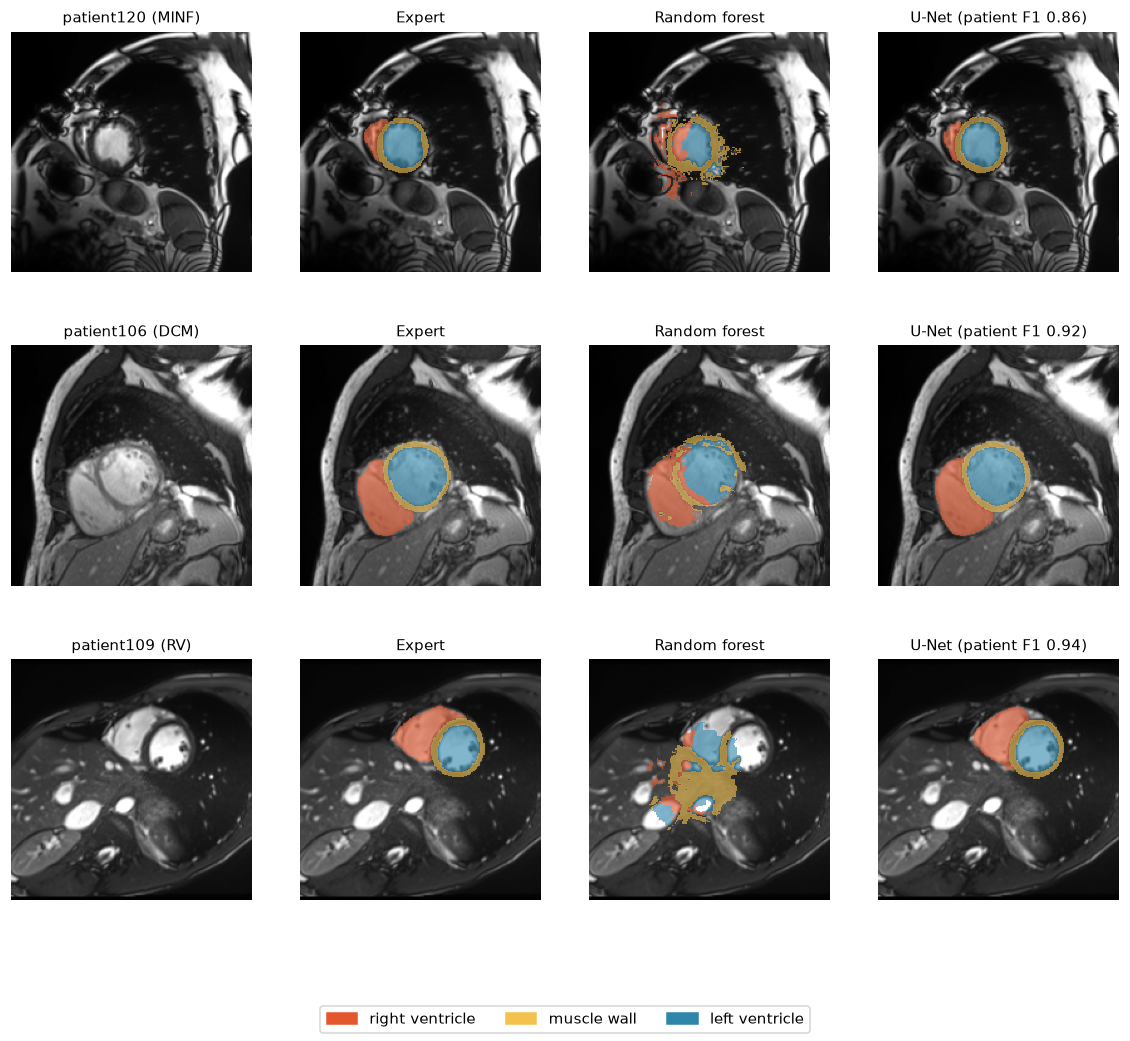

In [12]:
print("U-Net test macro F1 by subset:", json.dumps(breakdown(u_pred, te), indent=1))
display(pd.DataFrame([
    {"model": "Random forest", "parameters": "200 trees", "train": "3 min per fit, ~1 h with tuning", "s per slice": experiments["test_segmentation"]["random forest"]["seconds_per_slice"], "file MB": 272, "test macro F1": experiments["test_segmentation"]["random forest"]["test"]["macro_f1"]},
    {"model": "U-Net (final)", "parameters": 483204, "train": "30 min", "s per slice": experiments["test_segmentation"]["U-Net"]["seconds_per_slice"], "file MB": 2, "test macro F1": experiments["test_segmentation"]["U-Net"]["test"]["macro_f1"]},
]))
display(Image(os.path.join(OUT, "test_examples.png")))

## Appendix: full training code

The exact scripts we ran, in order. Set `RUN_TRAINING = True` in section 1 to rerun them. A rerun gives slightly different numbers, because training uses random shuffling and augmentation.

### A. Preprocessing and random forest (`acdc_forest_baseline.py`)

```python
"""CMPS 261 project, Group 26. ACDC heart segmentation: random forest baseline.

Each pixel of a 2D MRI slice is one row of a table, and the forest labels it as
background, right ventricle, muscle wall or left ventricle.

Run:  python acdc_forest_baseline.py [--prep-only]
Data: cmps261-work/data/acdc/extracted/database/training (the testing folder is never read)
Out:  results/ next to this file. Model files: cmps261-work/models/
"""
import csv, glob, json, os, re, sys, time, warnings

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage as ni
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")

# ---- settings ----
WORK = os.environ.get("ACDC_WORK", os.path.join((os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()), "cmps261-work"))   # data and models live here
DATA = os.path.join(WORK, "data/acdc/extracted/database/training")
MODEL_DIR = os.path.join(WORK, "models")
OUT = os.path.join((os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()), "results")
SEED = 261
SPACING = 1.5        # mm per pixel after resampling
CROP = 192           # slice size after centre crop or pad, in pixels
VAL_PER_GROUP = 4    # 4 x 5 groups = 20 validation patients
CLASSES = ["background", "right ventricle", "muscle wall", "left ventricle"]
FEATURES = ["brightness", "blur s=1", "blur s=2", "blur s=4", "blur s=8", "edge strength",
            "brightness vs surroundings", "y position", "x position", "distance from centre",
            "slice position"]


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


# ---- preprocessing ----
def crop_or_pad(a, size):
    """Centre crop or zero-pad a 2D array to size x size."""
    h, w = a.shape
    y0, x0 = max((h - size) // 2, 0), max((w - size) // 2, 0)
    c = a[y0:y0 + size, x0:x0 + size]
    out = np.zeros((size, size), a.dtype)
    oy, ox = (size - c.shape[0]) // 2, (size - c.shape[1]) // 2
    out[oy:oy + c.shape[0], ox:ox + c.shape[1]] = c
    return out


def load_patient(path, size=CROP):
    """Return the patient's labelled slices as a list of dicts, plus heart pixels kept and total."""
    slices, kept, total = [], 0, 0
    info = dict(re.findall(r"(\w+): (\S+)", open(os.path.join(path, "Info.cfg")).read()))
    name = os.path.basename(path)
    for moment, frame in (("ED", int(info["ED"])), ("ES", int(info["ES"]))):
        f = os.path.join(path, f"{name}_frame{frame:02d}.nii.gz")
        img = nib.load(f)
        vol = np.asarray(img.dataobj, dtype=np.float32)
        gt = np.asarray(nib.load(f.replace(".nii.gz", "_gt.nii.gz")).dataobj).astype(np.uint8)
        sy, sx = (float(s) for s in img.header.get_zooms()[:2])
        lo, hi = np.percentile(vol, [1, 99])          # brightness: clip, then scale to 0-1, per scan
        vol = np.clip((vol - lo) / (hi - lo), 0, 1)
        n = vol.shape[2]
        for k in range(n):
            a = ni.zoom(vol[:, :, k], (sy / SPACING, sx / SPACING), order=1)   # linear for images
            b = ni.zoom(gt[:, :, k], (sy / SPACING, sx / SPACING), order=0)    # nearest for labels
            b2 = crop_or_pad(b, size)
            total += int((b > 0).sum())
            kept += int((b2 > 0).sum())
            slices.append(dict(img=crop_or_pad(a, size), mask=b2, z=k / max(n - 1, 1),
                               patient=name, group=info["Group"], moment=moment, k=k))
    return slices, kept, total


GY, GX = np.mgrid[:CROP, :CROP]
GY, GX = ((GY - CROP / 2) / CROP).astype(np.float32), ((GX - CROP / 2) / CROP).astype(np.float32)
GR = np.hypot(GY, GX)


def features(s):
    """One row of 11 numbers per pixel."""
    a = s["img"]
    blur = [ni.gaussian_filter(a, g) for g in (1, 2, 4, 8)]
    cols = [a, *blur, ni.gaussian_gradient_magnitude(a, 2), a - blur[3], GY, GX, GR,
            np.full_like(a, s["z"])]
    return np.stack(cols, -1).reshape(-1, len(cols)).astype(np.float32)


def sample_rows(slices, fg_n, bg_n, rng):
    """Training rows: up to fg_n heart pixels and bg_n background pixels per slice."""
    X, Y = [], []
    for s in slices:
        F, l = features(s), s["mask"].ravel()
        fg, bg = np.flatnonzero(l > 0), np.flatnonzero(l == 0)
        fg = rng.choice(fg, min(len(fg), fg_n), replace=False) if len(fg) else fg
        bg = rng.choice(bg, min(len(bg), bg_n), replace=False)
        i = np.r_[fg, bg]
        X.append(F[i])
        Y.append(l[i])
    return np.vstack(X), np.concatenate(Y)


# ---- evaluation ----
def scores(cm):
    d = np.diag(cm).astype(float)
    p, r = d / np.maximum(cm.sum(0), 1), d / np.maximum(cm.sum(1), 1)
    f = 2 * p * r / np.maximum(p + r, 1e-9)
    return dict(precision=p[1:].round(4).tolist(), recall=r[1:].round(4).tolist(),
                f1=f[1:].round(4).tolist(), macro_f1=round(float(f[1:].mean()), 4),
                pixel_accuracy=round(float(d.sum() / cm.sum()), 4))


def predict_all(model, feats):
    return [model.predict(F).astype(np.uint8) for F in feats]


def evaluate(preds, slices):
    cm = np.zeros((4, 4), np.int64)
    for p, s in zip(preds, slices):
        cm += confusion_matrix(s["mask"].ravel(), p, labels=[0, 1, 2, 3])
    return cm


def forest(cfg):
    return RandomForestClassifier(n_estimators=cfg["trees"], max_depth=cfg["depth"],
                                  min_samples_leaf=cfg["leaf"], max_features=cfg["max_features"],
                                  class_weight=cfg["class_weight"], n_jobs=-1, random_state=SEED)


def main():
    os.makedirs(OUT, exist_ok=True)
    os.makedirs(MODEL_DIR, exist_ok=True)
    rng = np.random.default_rng(SEED)
    patients = sorted(glob.glob(glob.escape(DATA) + "/patient*"))

    t = time.time()
    data, kept, total = {}, 0, 0
    for p in patients:
        s, k, n = load_patient(p)
        data[os.path.basename(p)], kept, total = s, kept + k, total + n
    prep_s = time.time() - t
    log(f"preprocessed {sum(map(len, data.values()))} slices from {len(data)} patients in {prep_s:.0f}s")
    log(f"heart pixels kept after crop: {kept}/{total} = {kept / total:.5f}")
    if "--prep-only" in sys.argv:
        return

    names = sorted(data)
    groups = {n: data[n][0]["group"] for n in names}
    val = sorted(v for g in sorted(set(groups.values()))
                 for v in rng.choice([n for n in names if groups[n] == g], VAL_PER_GROUP, replace=False))
    train = [n for n in names if n not in val]
    json.dump(dict(train=train, val=val), open(os.path.join(OUT, "split.json"), "w"), indent=1)
    tr = [s for n in train for s in data[n]]
    va = [s for n in val for s in data[n]]
    va_feats = [features(s) for s in va]
    log(f"split: {len(train)} train patients ({len(tr)} slices), {len(val)} val patients ({len(va)} slices)")

    rows = []

    def trial(stage, cfg, X=None, Y=None):
        if X is None:
            X, Y = sample_rows(tr, cfg["fg"], cfg["bg"], np.random.default_rng(SEED))
        t0 = time.time()
        m = forest(cfg).fit(X, Y)
        fit_s = time.time() - t0
        t0 = time.time()
        sc = scores(evaluate(predict_all(m, va_feats), va))
        pred_s = time.time() - t0
        row = dict(stage=stage, **cfg, rows=len(Y), train_s=round(fit_s, 1), predict_s=round(pred_s, 1),
                   macro_f1=sc["macro_f1"], f1_rv=sc["f1"][0], f1_muscle=sc["f1"][1], f1_lv=sc["f1"][2],
                   mean_precision=round(float(np.mean(sc["precision"])), 4),
                   mean_recall=round(float(np.mean(sc["recall"])), 4),
                   pixel_accuracy=sc["pixel_accuracy"])
        rows.append(row)
        log(row)
        with open(os.path.join(OUT, "tuning.csv"), "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0]))
            w.writeheader()
            w.writerows(rows)
        return row

    # Stage 1: how many background pixels to train on, and whether to reweight classes.
    best = dict(fg=300, bg=300, trees=100, depth=20, leaf=5, max_features="sqrt", class_weight="balanced")
    results = [trial("1 sampling", {**best, "bg": bg, "class_weight": cw})
               for bg in (300, 1200, 3000) for cw in ("balanced", None)]
    top = max(results, key=lambda r: r["macro_f1"])
    best.update(bg=top["bg"], class_weight=top["class_weight"])

    # Stage 2: forest settings, one at a time, keeping any improvement.
    X, Y = sample_rows(tr, best["fg"], best["bg"], np.random.default_rng(SEED))
    score = top["macro_f1"]
    for key, values in (("depth", (12, 30)), ("leaf", (1, 20)), ("max_features", (0.5,)), ("trees", (200,))):
        for v in values:
            r = trial("2 forest", {**best, key: v}, X, Y)
            if r["macro_f1"] > score:
                score = r["macro_f1"]
                best[key] = v
    log("best config", best)

    # Final model: refit on the training patients, full validation report.
    t0 = time.time()
    model = forest(best).fit(X, Y)
    fit_s = time.time() - t0
    t0 = time.time()
    preds = predict_all(model, va_feats)
    pred_s = time.time() - t0
    cm = evaluate(preds, va)
    joblib.dump(model, os.path.join(MODEL_DIR, "acdc_forest.joblib"), compress=3)

    def sub(cond):
        idx = [i for i, s in enumerate(va) if cond(s)]
        return scores(evaluate([preds[i] for i in idx], [va[i] for i in idx]))

    third = lambda s: "top" if s["z"] < 1 / 3 else ("middle" if s["z"] < 2 / 3 else "bottom")
    per_patient = {n: sub(lambda s, n=n: s["patient"] == n)["macro_f1"] for n in val}
    report = dict(
        best_config=best, training_rows=len(Y), train_seconds=round(fit_s, 1),
        predict_seconds_val=round(pred_s, 1), preprocess_seconds=round(prep_s, 1),
        heart_pixels_kept=round(kept / total, 5), validation=scores(cm), confusion_matrix=cm.tolist(),
        all_background_accuracy=round(float(cm[0].sum() / cm.sum()), 4),
        by_group={g: sub(lambda s, g=g: s["group"] == g)["macro_f1"] for g in sorted(set(groups.values()))},
        by_moment={m: sub(lambda s, m=m: s["moment"] == m)["macro_f1"] for m in ("ED", "ES")},
        by_slice_position={p: sub(lambda s, p=p: third(s) == p)["macro_f1"] for p in ("top", "middle", "bottom")},
        per_patient=per_patient,
        feature_importance=dict(sorted(zip(FEATURES, model.feature_importances_.round(4).tolist()),
                                       key=lambda kv: -kv[1])),
    )

    # Split sensitivity: 5-fold by patient with the chosen settings.
    cv = []
    y = [groups[n] for n in names]
    for i, (a, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(names, y)):
        ftr = [s for j in a for s in data[names[j]]]
        fva = [s for j in b for s in data[names[j]]]
        Xf, Yf = sample_rows(ftr, best["fg"], best["bg"], np.random.default_rng(SEED))
        m = forest(best).fit(Xf, Yf)
        c = scores(evaluate([m.predict(features(s)).astype(np.uint8) for s in fva], fva))["macro_f1"]
        cv.append(c)
        log(f"fold {i + 1}: macro F1 {c}")
    report["cv5_macro_f1"] = cv
    report["cv5_mean"] = round(float(np.mean(cv)), 4)
    report["cv5_std"] = round(float(np.std(cv)), 4)
    json.dump(report, open(os.path.join(OUT, "forest_results.json"), "w"), indent=1)

    # Figure: worst, median and best validation patients, middle slice at the full moment.
    order = sorted(val, key=per_patient.get)
    pick = [order[0], order[len(order) // 2], order[-1]]
    colours = ListedColormap(["#e4572e", "#f2c14e", "#2e86ab"])
    fig, ax = plt.subplots(3, 3, figsize=(10, 10.5))
    for r, n in enumerate(pick):
        idx = [i for i, s in enumerate(va) if s["patient"] == n and s["moment"] == "ED"]
        i = idx[len(idx) // 2]
        pred = preds[i].reshape(CROP, CROP)
        for c, (lab, title) in enumerate(((None, "MRI slice"), (va[i]["mask"], "Expert labels"), (pred, "Forest prediction"))):
            ax[r, c].imshow(va[i]["img"].T, cmap="gray")
            if lab is not None:
                ax[r, c].imshow(np.ma.masked_where(lab.T == 0, lab.T), cmap=colours, vmin=1, vmax=3,
                                alpha=.6, interpolation="nearest")
            ax[r, c].set_title(f"{title}" + (f"\n{n} ({va[i]['group']}), patient macro F1 {per_patient[n]:.2f}" if c == 0 else ""), fontsize=10)
            ax[r, c].axis("off")
    fig.legend(handles=[Patch(color=colours(i), label=CLASSES[i + 1]) for i in range(3)], loc="lower center", ncol=3)
    fig.savefig(os.path.join(OUT, "forest_examples.png"), dpi=120, bbox_inches="tight")
    log("DONE", report["validation"], "cv", report["cv5_mean"], report["cv5_std"])


if __name__ == "__main__":
    main()
```

In [13]:
# Runs the script above, so the code is exactly what produced our results.
if RUN_TRAINING:
    %run acdc_forest_baseline.py

### B. Diagnosis baseline (`acdc_diagnosis_baseline.py`)

```python
"""CMPS 261 project, Group 26. ACDC diagnosis from heart measurements.

One row per patient: volumes, ejection fraction, muscle mass and wall thickness, measured
from the EXPERT outlines. This is an upper bound: the real pipeline would measure from
predicted outlines. Labels come from Info.cfg. The testing folder is never read.

Run: python acdc_diagnosis_baseline.py
"""
import glob, json, os, re, time, warnings

import joblib
import nibabel as nib
import numpy as np
from scipy import ndimage as ni
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
WORK = os.environ.get("ACDC_WORK", os.path.join((os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()), "cmps261-work"))
DATA = os.path.join(WORK, "data/acdc/extracted/database/training")
OUT = os.path.join((os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()), "results")
RV, MUSCLE, LV = 1, 2, 3
GROUPS = ["NOR", "MINF", "DCM", "HCM", "RV"]


def measure(path):
    info = dict(re.findall(r"(\w+): (\S+)", open(path + "/Info.cfg").read()))
    name = os.path.basename(path)

    def scan(frame):
        n = nib.load(f"{path}/{name}_frame{int(frame):02d}_gt.nii.gz")
        return np.asarray(n.dataobj).astype(np.uint8), tuple(float(z) for z in n.header.get_zooms())

    ed, z = scan(info["ED"])
    es, _ = scan(info["ES"])
    ml = z[0] * z[1] * z[2] / 1000                      # one voxel, in mL
    lv_ed, lv_es = (ed == LV).sum() * ml, (es == LV).sum() * ml
    rv_ed, rv_es = (ed == RV).sum() * ml, (es == RV).sum() * ml
    mass = (ed == MUSCLE).sum() * ml * 1.05             # heart muscle is about 1.05 g/mL
    h, w = float(info["Height"]), float(info["Weight"])
    bsa = np.sqrt(h * w / 3600)                         # Mosteller body surface area, m2
    thick = max(2 * ni.distance_transform_edt(ed[:, :, k] == MUSCLE, sampling=z[:2]).max()
                for k in range(ed.shape[2]))            # thickest wall, roughly, in mm
    row = dict(lv_edv=lv_ed, lv_esv=lv_es, lv_ef=(lv_ed - lv_es) / lv_ed,
               rv_edv=rv_ed, rv_esv=rv_es, rv_ef=(rv_ed - rv_es) / rv_ed,
               muscle_mass=mass, lv_edv_per_m2=lv_ed / bsa, rv_edv_per_m2=rv_ed / bsa,
               mass_per_m2=mass / bsa, rv_lv_ratio=rv_ed / lv_ed, max_thickness=thick)
    return row, info["Group"], name


rows, y, names = zip(*[measure(p) for p in sorted(glob.glob(glob.escape(DATA) + "/patient*"))])
cols = list(rows[0])
X = np.array([[r[c] for c in cols] for r in rows])
y = np.array(y)

models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "decision tree": DecisionTreeClassifier(max_depth=4, random_state=261),
    "random forest": RandomForestClassifier(n_estimators=300, n_jobs=2, random_state=261),
}
results = {}
for name, m in models.items():
    t, accs, f1s, cm = time.time(), [], [], np.zeros((5, 5), int)
    for a, b in RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=261).split(X, y):
        p = m.fit(X[a], y[a]).predict(X[b])
        accs.append((p == y[b]).mean())
        f1s.append(f1_score(y[b], p, average="macro"))
        cm += confusion_matrix(y[b], p, labels=GROUPS)
    results[name] = dict(accuracy=round(float(np.mean(accs)), 4), accuracy_std=round(float(np.std(accs)), 4),
                         macro_f1=round(float(np.mean(f1s)), 4), seconds=round(time.time() - t, 1),
                         confusion_matrix=cm.tolist())
    print(name, {k: v for k, v in results[name].items() if k != "confusion_matrix"}, flush=True)
    print(cm, flush=True)

imp = RandomForestClassifier(n_estimators=300, n_jobs=2, random_state=261).fit(X, y).feature_importances_
results["feature_importance"] = dict(sorted(zip(cols, imp.round(4).tolist()), key=lambda kv: -kv[1]))
results["group_order"] = GROUPS
print(results["feature_importance"])
os.makedirs(OUT, exist_ok=True)
json.dump(results, open(OUT + "/diagnosis_results.json", "w"), indent=1)

# Save the logistic regression, fitted on all 100 training patients.
final = models["logistic regression"].fit(X, y)
os.makedirs(os.path.join(WORK, "models"), exist_ok=True)
joblib.dump(dict(model=final, features=cols), os.path.join(WORK, "models/acdc_diagnosis_logreg.joblib"))
```

In [14]:
# Runs the script above, so the code is exactly what produced our results.
if RUN_TRAINING:
    %run acdc_diagnosis_baseline.py

### C. U-Net pilot (`acdc_unet_pilot.py`)

```python
"""CMPS 261 project, Group 26. ACDC heart segmentation: small U-Net pilot.

Same preprocessing, patient split and scoring as acdc_forest_baseline.py, so the two
models are directly comparable. Whole slices go in; a label per pixel comes out.
This is a first, untuned run. The testing folder is never read.

Run: python acdc_unet_pilot.py
"""
import glob, json, os, sys, time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

sys.path.insert(0, (os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()))
from acdc_forest_baseline import CLASSES, CROP, DATA, MODEL_DIR, OUT, load_patient, log, scores

EPOCHS, BATCH, LR, BASE = 30, 16, 1e-3, 16
torch.manual_seed(261)
np.random.seed(261)
device = "mps" if torch.backends.mps.is_available() else "cpu"


def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())


class UNet(nn.Module):
    """Shrinks the image 3 times to see context, then expands it back, reusing detail."""

    def __init__(self, b=BASE):
        super().__init__()
        self.d1, self.d2, self.d3 = block(1, b), block(b, 2 * b), block(2 * b, 4 * b)
        self.mid = block(4 * b, 8 * b)
        self.u3, self.c3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, 2), block(8 * b, 4 * b)
        self.u2, self.c2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, 2), block(4 * b, 2 * b)
        self.u1, self.c1 = nn.ConvTranspose2d(2 * b, b, 2, 2), block(2 * b, b)
        self.out = nn.Conv2d(b, 4, 1)
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        a = self.d1(x)
        c = self.d2(self.pool(a))
        d = self.d3(self.pool(c))
        m = self.mid(self.pool(d))
        d = self.c3(torch.cat([self.u3(m), d], 1))
        c = self.c2(torch.cat([self.u2(d), c], 1))
        a = self.c1(torch.cat([self.u1(c), a], 1))
        return self.out(a)


def tensors(slices):
    x = torch.tensor(np.stack([s["img"] for s in slices]))[:, None].float()
    y = torch.tensor(np.stack([s["mask"] for s in slices])).long()
    return x, y


def predict(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i + 32].to(device)).argmax(1).cpu() for i in range(0, len(x), 32)])


def confusion(pred, y):
    return np.bincount((y.reshape(-1) * 4 + pred.reshape(-1)).numpy(), minlength=16).reshape(4, 4)


split = json.load(open(os.path.join(OUT, "split.json")))
data = {os.path.basename(p): load_patient(p)[0] for p in sorted(glob.glob(glob.escape(DATA) + "/patient*"))}
tr = [s for n in split["train"] for s in data[n]]
va = [s for n in split["val"] for s in data[n]]
xt, yt = tensors(tr)
xv, yv = tensors(va)

model = UNet().to(device)
params = sum(p.numel() for p in model.parameters())
log(f"device {device}, {params} parameters, {len(tr)} train slices, {len(va)} val slices")
opt = torch.optim.Adam(model.parameters(), lr=LR)
loss_fn = nn.CrossEntropyLoss()

history, best, start = [], -1.0, time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    order, total = torch.randperm(len(xt)), 0.0
    for i in range(0, len(xt), BATCH):
        j = order[i:i + BATCH]
        opt.zero_grad()
        loss = loss_fn(model(xt[j].to(device)), yt[j].to(device))
        loss.backward()
        opt.step()
        total += loss.item() * len(j)
    sc = scores(confusion(predict(model, xv), yv))
    history.append(dict(epoch=epoch, train_loss=round(total / len(xt), 4), val_macro_f1=sc["macro_f1"],
                        seconds=round(time.time() - start, 1)))
    log(history[-1])
    if sc["macro_f1"] > best:
        best = sc["macro_f1"]
        torch.save(model.state_dict(), os.path.join(MODEL_DIR, "acdc_unet_pilot.pt"))

model.load_state_dict(torch.load(os.path.join(MODEL_DIR, "acdc_unet_pilot.pt")))
t0 = time.time()
pred = predict(model, xv)
pred_s = time.time() - t0
cm = confusion(pred, yv)


def sub(cond):
    i = [k for k, s in enumerate(va) if cond(s)]
    return scores(confusion(pred[i], yv[i]))["macro_f1"]


third = lambda s: "top" if s["z"] < 1 / 3 else ("middle" if s["z"] < 2 / 3 else "bottom")
per_patient = {n: sub(lambda s, n=n: s["patient"] == n) for n in split["val"]}
report = dict(device=device, parameters=params, epochs=EPOCHS, batch=BATCH, learning_rate=LR,
              train_seconds=history[-1]["seconds"], predict_seconds_val=round(pred_s, 1),
              best_epoch=max(history, key=lambda h: h["val_macro_f1"])["epoch"],
              validation=scores(cm), confusion_matrix=cm.tolist(),
              by_group={g: sub(lambda s, g=g: s["group"] == g) for g in sorted({s["group"] for s in va})},
              by_moment={m: sub(lambda s, m=m: s["moment"] == m) for m in ("ED", "ES")},
              by_slice_position={p: sub(lambda s, p=p: third(s) == p) for p in ("top", "middle", "bottom")},
              per_patient=per_patient, history=history)
json.dump(report, open(os.path.join(OUT, "unet_pilot_results.json"), "w"), indent=1)

# Figure: the same three patients as the forest figure.
forest = json.load(open(os.path.join(OUT, "forest_results.json")))["per_patient"]
order = sorted(split["val"], key=forest.get)
pick = [order[0], order[len(order) // 2], order[-1]]
colours = ListedColormap(["#e4572e", "#f2c14e", "#2e86ab"])
fig, ax = plt.subplots(3, 3, figsize=(10, 10.5))
for r, n in enumerate(pick):
    idx = [i for i, s in enumerate(va) if s["patient"] == n and s["moment"] == "ED"]
    i = idx[len(idx) // 2]
    for c, (lab, title) in enumerate(((None, "MRI slice"), (va[i]["mask"], "Expert labels"), (pred[i].numpy(), "U-Net prediction"))):
        ax[r, c].imshow(va[i]["img"].T, cmap="gray")
        if lab is not None:
            ax[r, c].imshow(np.ma.masked_where(lab.T == 0, lab.T), cmap=colours, vmin=1, vmax=3, alpha=.6, interpolation="nearest")
        ax[r, c].set_title(title + (f"\n{n} ({va[i]['group']}), patient macro F1 {per_patient[n]:.2f}" if c == 0 else ""), fontsize=10)
        ax[r, c].axis("off")
fig.legend(handles=[Patch(color=colours(i), label=CLASSES[i + 1]) for i in range(3)], loc="lower center", ncol=3)
fig.savefig(os.path.join(OUT, "unet_pilot_examples.png"), dpi=120, bbox_inches="tight")
log("DONE", report["validation"])
```

In [15]:
# Runs the script above, so the code is exactly what produced our results.
if RUN_TRAINING:
    %run acdc_unet_pilot.py

### D. U-Net variants, diagnosis tuning and final test (`acdc_experiments.py`)

```python
"""CMPS 261 project, Group 26. Final experiments on ACDC.

1. Forest without position features (does it just memorise where the heart usually is?)
2. U-Net variants: augmentation, Dice loss, wider network, longer training
3. Diagnosis models: tuned logistic regression, small neural network, random forest
4. Final test on the 50 untouched test patients: segmentation, heart measurements,
   diagnosis from predicted outlines, and whether model confidence can be trusted.

Model choices are made on the 20 validation patients only. The test set is used once, at the end.
Run: python acdc_experiments.py   (add --smoke for a 2-minute check)
"""
import csv, glob, json, os, re, sys, time

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as Fn
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage as ni
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, (os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()))
from acdc_forest_baseline import (CLASSES, CROP, DATA, MODEL_DIR, OUT, SPACING, features, forest,
                                  load_patient, log, sample_rows, scores)

SMOKE = "--smoke" in sys.argv
TEST_DATA = DATA.replace("training", "testing")
device = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(261)
np.random.seed(261)
RESULTS = {}


def save():
    json.dump(RESULTS, open(os.path.join(OUT, "experiments" + ("_smoke" if SMOKE else "") + ".json"), "w"), indent=1)


def confusion(pred, true):
    return np.bincount((np.asarray(true).reshape(-1).astype(np.int64) * 4 + np.asarray(pred).reshape(-1)), minlength=16).reshape(4, 4)


def breakdown(preds, slices):
    """Macro F1 overall and by moment, slice position and group."""
    def sub(cond):
        i = [k for k, s in enumerate(slices) if cond(s)]
        return scores(sum(confusion(preds[k], slices[k]["mask"]) for k in i))["macro_f1"]
    third = lambda s: "first third" if s["z"] < 1 / 3 else ("middle" if s["z"] < 2 / 3 else "last third")
    return dict(by_moment={m: sub(lambda s, m=m: s["moment"] == m) for m in ("ED", "ES")},
                by_slice_position={p: sub(lambda s, p=p: third(s) == p) for p in ("first third", "middle", "last third")},
                by_group={g: sub(lambda s, g=g: s["group"] == g) for g in sorted({s["group"] for s in slices})})


# ---------------- data ----------------
split = json.load(open(os.path.join(OUT, "split.json")))
train_names, val_names = split["train"], split["val"]
test_paths = sorted(glob.glob(glob.escape(TEST_DATA) + "/patient*"))
if SMOKE:
    train_names, val_names, test_paths = train_names[::8], val_names[:3], test_paths[::17]
data = {n: load_patient(os.path.join(DATA, n))[0] for n in train_names + val_names}
test = {os.path.basename(p): load_patient(p)[0] for p in test_paths}
tr = [s for n in train_names for s in data[n]]
va = [s for n in val_names for s in data[n]]
te = [s for n in sorted(test) for s in test[n]]
log(f"{len(tr)} train, {len(va)} val, {len(te)} test slices; device {device}")


# ---------------- 1. forest without position features ----------------
NO_POS = [0, 1, 2, 3, 4, 5, 6, 10]          # drop y, x and distance from centre
best_forest = dict(fg=300, bg=1200, trees=200, depth=20, leaf=5, max_features="sqrt", class_weight=None)
if SMOKE:
    best_forest.update(trees=10, bg=200)
X, Y = sample_rows(tr, best_forest["fg"], best_forest["bg"], np.random.default_rng(261))
t0 = time.time()
m = forest(best_forest).fit(X[:, NO_POS], Y)
fit_s = time.time() - t0
cm = sum(confusion(m.predict(features(s)[:, NO_POS]), s["mask"]) for s in va)
RESULTS["forest_without_position"] = dict(validation=scores(cm), train_seconds=round(fit_s, 1),
                                          with_position_macro_f1=0.5901)
log("forest without position", RESULTS["forest_without_position"]["validation"])
del m, X, Y
save()


# ---------------- 2. U-Net variants ----------------
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())


class UNet(nn.Module):
    """Same design as the pilot: shrink 3 times to see context, expand back to reuse detail."""

    def __init__(self, b=16):
        super().__init__()
        self.d1, self.d2, self.d3 = block(1, b), block(b, 2 * b), block(2 * b, 4 * b)
        self.mid = block(4 * b, 8 * b)
        self.u3, self.c3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, 2), block(8 * b, 4 * b)
        self.u2, self.c2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, 2), block(4 * b, 2 * b)
        self.u1, self.c1 = nn.ConvTranspose2d(2 * b, b, 2, 2), block(2 * b, b)
        self.out, self.pool = nn.Conv2d(b, 4, 1), nn.MaxPool2d(2)

    def forward(self, x):
        a = self.d1(x)
        c = self.d2(self.pool(a))
        d = self.d3(self.pool(c))
        m = self.mid(self.pool(d))
        d = self.c3(torch.cat([self.u3(m), d], 1))
        c = self.c2(torch.cat([self.u2(d), c], 1))
        return self.out(self.c1(torch.cat([self.u1(c), a], 1)))


def tensors(slices):
    return (torch.tensor(np.stack([s["img"] for s in slices]))[:, None].float(),
            torch.tensor(np.stack([s["mask"] for s in slices])).long())


def augment(x, y):
    """Random small rotation (±15°), shift (±10%) and zoom (0.9–1.1), same for image and outline.
    Real scans are not always centred or aligned the same way, so the model should not rely on that."""
    n = len(x)
    a = (torch.rand(n) * 2 - 1) * np.pi / 12
    s = 0.9 + torch.rand(n) * 0.2
    t = (torch.rand(n, 2) * 2 - 1) * 0.1
    theta = torch.stack([torch.stack([torch.cos(a) / s, -torch.sin(a) / s, t[:, 0]], 1),
                         torch.stack([torch.sin(a) / s, torch.cos(a) / s, t[:, 1]], 1)], 1)
    grid = Fn.affine_grid(theta, x.shape, align_corners=False)
    x = Fn.grid_sample(x, grid, mode="bilinear", align_corners=False)
    y = Fn.grid_sample(y[:, None].float(), grid, mode="nearest", align_corners=False)[:, 0].long()
    return x, y


def dice_loss(logits, y):
    """1 − average overlap of the three heart structures. Rewards overlap directly,
    which matters because each structure is only about 1% of the pixels."""
    p = logits.softmax(1)[:, 1:]
    t = Fn.one_hot(y, 4).permute(0, 3, 1, 2)[:, 1:].float()
    inter = (p * t).sum((0, 2, 3))
    return 1 - ((2 * inter + 1) / (p.sum((0, 2, 3)) + t.sum((0, 2, 3)) + 1)).mean()


def predict(model, x, probs=False):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), 32):
            p = model(x[i:i + 32].to(device)).softmax(1).cpu()
            out.append(p if probs else p.argmax(1))
    return torch.cat(out)


xt, yt = tensors(tr)
xv, yv = tensors(va)
xe, ye = tensors(te)
VARIANTS = [
    dict(name="B: + augmentation", base=16, aug=True, dice=False, epochs=40),
    dict(name="C: + augmentation + Dice loss", base=16, aug=True, dice=True, epochs=40),
    dict(name="D: wider (32) + aug + Dice", base=32, aug=True, dice=True, epochs=40),
    dict(name="E: aug + Dice, 80 epochs", base=16, aug=True, dice=True, epochs=80),
]
RESULTS["unet_pilot"] = dict(name="A: pilot (no augmentation, cross-entropy)", base=16, epochs=30,
                             val_macro_f1=0.9017, parameters=483204, train_seconds=617.8)
RESULTS["unet_variants"] = []
curves = {}
for v in VARIANTS:
    if SMOKE:
        v = {**v, "epochs": 1}
    torch.manual_seed(261)
    model = UNet(v["base"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    best, hist, start = -1, [], time.time()
    path = os.path.join(MODEL_DIR, f"acdc_unet_{v['name'][0]}{'_smoke' if SMOKE else ''}.pt")
    for epoch in range(1, v["epochs"] + 1):
        model.train()
        order = torch.randperm(len(xt))
        for i in range(0, len(xt), 16):
            xb, yb = xt[order[i:i + 16]], yt[order[i:i + 16]]
            if v["aug"]:
                xb, yb = augment(xb, yb)
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            out = model(xb)
            loss = Fn.cross_entropy(out, yb) + (dice_loss(out, yb) if v["dice"] else 0)
            loss.backward()
            opt.step()
        f1 = scores(confusion(predict(model, xv), yv))["macro_f1"]
        hist.append(f1)
        if f1 > best:
            best, best_epoch = f1, epoch
            torch.save(model.state_dict(), path)
    train_s = time.time() - start
    curves[v["name"]] = hist
    row = dict(name=v["name"], base=v["base"], augmentation=v["aug"], dice=v["dice"], epochs=v["epochs"],
               parameters=sum(p.numel() for p in model.parameters()), train_seconds=round(train_s, 1),
               val_macro_f1=best, best_epoch=best_epoch,
               last5_mean=round(float(np.mean(hist[-5:])), 4), last5_min=round(float(np.min(hist[-5:])), 4),
               file_mb=round(os.path.getsize(path) / 1e6, 2), path=path)
    RESULTS["unet_variants"].append(row)
    log(row)
    save()

pick = max(RESULTS["unet_variants"], key=lambda r: r["val_macro_f1"])
RESULTS["unet_chosen"] = pick["name"]
model = UNet(pick["base"]).to(device)
model.load_state_dict(torch.load(pick["path"]))
fig, ax = plt.subplots(figsize=(7, 4))
for k, h in curves.items():
    ax.plot(range(1, len(h) + 1), h, label=k)
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro F1"); ax.set_ylim(0.6, 0.95); ax.legend(fontsize=8)
fig.savefig(os.path.join(OUT, "unet_variants_curves.png"), dpi=120, bbox_inches="tight")


# ---------------- 3. heart measurements and diagnosis models ----------------
def meta(path):
    info = dict(re.findall(r"(\w+): (\S+)", open(os.path.join(path, "Info.cfg")).read()))
    z = float(nib.load(glob.glob(glob.escape(path) + "/*_frame??.nii.gz")[0]).header.get_zooms()[2])
    return info, z


def measure(ed, es, z, h, w):
    """12 measurements from outline stacks (slices x 192 x 192, at 1.5 mm pixels)."""
    ml = SPACING * SPACING * z / 1000
    lv_ed, lv_es = (ed == 3).sum() * ml, (es == 3).sum() * ml
    rv_ed, rv_es = (ed == 1).sum() * ml, (es == 1).sum() * ml
    mass = (ed == 2).sum() * ml * 1.05
    bsa = np.sqrt(h * w / 3600)
    thick = max(2 * ni.distance_transform_edt(sl == 2, sampling=SPACING).max() for sl in ed)
    lv_ef = (lv_ed - lv_es) / max(lv_ed, 1e-6)
    rv_ef = (rv_ed - rv_es) / max(rv_ed, 1e-6)
    return [lv_ed, lv_es, lv_ef, rv_ed, rv_es, rv_ef, mass, lv_ed / bsa, rv_ed / bsa, mass / bsa,
            rv_ed / max(lv_ed, 1e-6), thick]


MEASURES = ["lv_edv", "lv_esv", "lv_ef", "rv_edv", "rv_esv", "rv_ef", "muscle_mass", "lv_edv_per_m2",
            "rv_edv_per_m2", "mass_per_m2", "rv_lv_ratio", "max_thickness"]


def patient_table(names, root, slices, preds=None):
    """One row of measurements per patient, from expert outlines or from predictions."""
    rows, groups = [], []
    for n in names:
        info, z = meta(os.path.join(root, n))
        idx = {m: [i for i, s in enumerate(slices) if s["patient"] == n and s["moment"] == m] for m in ("ED", "ES")}
        get = (lambda i: slices[i]["mask"]) if preds is None else (lambda i: np.asarray(preds[i]).reshape(CROP, CROP))
        ed = np.stack([get(i) for i in idx["ED"]])
        es = np.stack([get(i) for i in idx["ES"]])
        rows.append(measure(ed, es, z, float(info["Height"]), float(info["Weight"])))
        groups.append(info.get("Group", "?"))
    return np.array(rows), np.array(groups)


all_train = sorted(train_names + val_names)
everything = [s for n in all_train for s in data[n]]
Xd, yd = patient_table(all_train, DATA, everything)
cv = RepeatedStratifiedKFold(n_splits=5 if not SMOKE else 2, n_repeats=5 if not SMOKE else 1, random_state=261)
candidates = {f"logistic regression C={c}": make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000))
              for c in (0.01, 0.1, 1, 10, 100)}
candidates.update({f"neural network (16 hidden) alpha={a}": make_pipeline(StandardScaler(), MLPClassifier((16,), alpha=a, max_iter=5000, random_state=261))
                   for a in (0.001, 0.01, 0.1, 1)})
candidates["random forest"] = RandomForestClassifier(n_estimators=300, random_state=261, n_jobs=-1)
RESULTS["diagnosis_cv"] = {}
for k, mdl in candidates.items():
    sc = cross_val_score(mdl, Xd, yd, cv=cv, scoring="accuracy")
    RESULTS["diagnosis_cv"][k] = dict(accuracy=round(float(sc.mean()), 4), std=round(float(sc.std()), 4))
    log(k, RESULTS["diagnosis_cv"][k])
best_lr = max((k for k in candidates if k.startswith("logistic")), key=lambda k: RESULTS["diagnosis_cv"][k]["accuracy"])
best_nn = max((k for k in candidates if k.startswith("neural")), key=lambda k: RESULTS["diagnosis_cv"][k]["accuracy"])
RESULTS["diagnosis_chosen"] = dict(classical=best_lr, neural=best_nn)
clf = {k: candidates[k].fit(Xd, yd) for k in (best_lr, best_nn)}
joblib.dump(dict(model=clf[best_lr], features=MEASURES), os.path.join(MODEL_DIR, "acdc_diagnosis_final.joblib"))
save()


# ---------------- 4. final test (used once) ----------------
log("final test")
forest_model = joblib.load(os.path.join(MODEL_DIR, "acdc_forest.joblib"))
t0 = time.time()
f_prob = [forest_model.predict_proba(features(s)) for s in te]
forest_s = time.time() - t0
f_pred = [p.argmax(1) for p in f_prob]
t0 = time.time()
u_prob = predict(model, xe, probs=True)
unet_s = time.time() - t0
u_pred = [p.argmax(0).numpy().reshape(-1) for p in u_prob]


def confidence(probs, preds, slices):
    """On pixels the model calls heart: is its confidence close to how often it is right?"""
    conf, right = [], []
    for p, q, s in zip(probs, preds, slices):
        p = np.asarray(p).reshape(4, -1).T if p.ndim == 3 else np.asarray(p)
        keep = q > 0
        conf.append(p.max(1)[keep])
        right.append((q == s["mask"].reshape(-1))[keep])
    conf, right = np.concatenate(conf), np.concatenate(right)
    bins = np.minimum((conf * 10).astype(int), 9)
    ece = sum(abs(conf[bins == b].mean() - right[bins == b].mean()) * (bins == b).mean() for b in range(10) if (bins == b).any())
    return dict(calibration_error=round(float(ece), 4), mean_conf_when_right=round(float(conf[right].mean()), 4),
                mean_conf_when_wrong=round(float(conf[~right].mean()), 4) if (~right).any() else None,
                share_right=round(float(right.mean()), 4))


seg = {}
for name, preds, probs, secs in (("random forest", f_pred, f_prob, forest_s), ("U-Net", u_pred, [p.numpy() for p in u_prob], unet_s)):
    cm = sum(confusion(p, s["mask"]) for p, s in zip(preds, te))
    seg[name] = dict(test=scores(cm), seconds_per_slice=round(secs / len(te), 4), **breakdown(preds, te),
                     confidence=confidence(probs, preds, te))
    log(name, seg[name]["test"])
seg["all_background_accuracy"] = round(float(cm[0].sum() / cm.sum()), 4)
RESULTS["test_segmentation"] = seg

names = sorted(test)
X_true, y_test = patient_table(names, TEST_DATA, te)
X_unet, _ = patient_table(names, TEST_DATA, te, u_pred)
X_forest, _ = patient_table(names, TEST_DATA, te, f_pred)
diag = {}
for k, c in clf.items():
    diag[k] = {src: round(float((c.predict(Xs) == y_test).mean()), 4)
               for src, Xs in (("expert outlines", X_true), ("U-Net outlines", X_unet), ("forest outlines", X_forest))}
    log(k, diag[k])
err = lambda Xs, j: round(float(np.mean(np.abs(Xs[:, j] - X_true[:, j]))), 3)
RESULTS["test_diagnosis"] = dict(accuracy=diag, patients=len(names),
    mean_abs_error={src: dict(lv_ef_points=round(100 * err(Xs, 2), 1), rv_ef_points=round(100 * err(Xs, 5), 1),
                              lv_edv_ml=err(Xs, 0), rv_edv_ml=err(Xs, 3))
                    for src, Xs in (("U-Net outlines", X_unet), ("forest outlines", X_forest))})
save()

# Figure: 3 test patients, middle slice at the full moment: MRI, expert, forest, U-Net.
pp = {n: scores(sum(confusion(u_pred[i], te[i]["mask"]) for i, s in enumerate(te) if s["patient"] == n))["macro_f1"] for n in names}
order = sorted(names, key=pp.get)
colours = ListedColormap(["#e4572e", "#f2c14e", "#2e86ab"])
fig, ax = plt.subplots(3, 4, figsize=(13, 10.5))
for r, n in enumerate([order[0], order[len(order) // 2], order[-1]]):
    idx = [i for i, s in enumerate(te) if s["patient"] == n and s["moment"] == "ED"]
    i = idx[len(idx) // 2]
    for c, (lab, title) in enumerate(((None, f"{n} ({te[i]['group']})"), (te[i]["mask"], "Expert"),
                                      (f_pred[i].reshape(CROP, CROP), "Random forest"), (u_pred[i].reshape(CROP, CROP), f"U-Net (patient F1 {pp[n]:.2f})"))):
        ax[r, c].imshow(te[i]["img"].T, cmap="gray")
        if lab is not None:
            ax[r, c].imshow(np.ma.masked_where(lab.T == 0, lab.T), cmap=colours, vmin=1, vmax=3, alpha=.6, interpolation="nearest")
        ax[r, c].set_title(title, fontsize=10)
        ax[r, c].axis("off")
fig.legend(handles=[Patch(color=colours(i), label=CLASSES[i + 1]) for i in range(3)], loc="lower center", ncol=3)
fig.savefig(os.path.join(OUT, "test_examples.png"), dpi=110, bbox_inches="tight")
log("DONE")
```

In [16]:
# Runs the script above, so the code is exactly what produced our results.
if RUN_TRAINING:
    %run acdc_experiments.py